In [1]:
import numpy as np
import pandas as pd

In [2]:
np.random.seed(23)

mu_vec1 = np.array([0,0,0])
cov_mat1 = np.array([[1,0,0],[0,1,0],[0,0,1]])

class1_sample = np.random.multivariate_normal(
    mu_vec1, cov_mat1, 20
)

df = pd.DataFrame(
    class1_sample,
    columns=['feature1','feature2','feature3']
)

df['target'] = 1

In [3]:
mu_vec2 = np.array([1,1,1])

cov_mat2 = np.array([[1,0,0],[0,1,0],[0,0,1]])

class2_sample = np.random.multivariate_normal(
    mu_vec2, cov_mat2, 20
)

df1 = pd.DataFrame(
    class2_sample,
    columns=['feature1','feature2','feature3']
)

df1['target'] = 0

In [4]:
df = pd.concat([df, df1], ignore_index=True)

df = df.sample(40)

In [5]:
df.head()

,feature1,feature2,feature3,target
2,-0.367548,-1.137460,-1.322148,1
34,0.177061,-0.598109,1.226512,0
14,0.420623,0.411620,-0.071324,1
11,1.968435,-0.547788,-0.679418,1
12,-2.506230,0.146960,0.606195,1


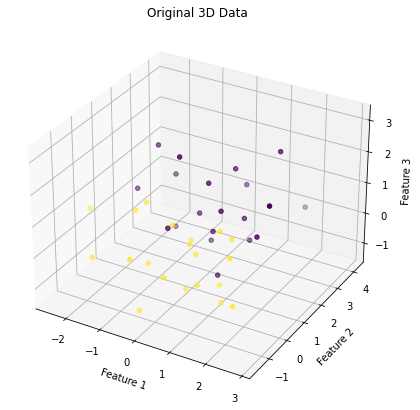

In [6]:
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(df['feature1'], df['feature2'],
           df['feature3'], c=df['target'])

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')

plt.title('Original 3D Data')
plt.show()

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])

In [8]:
covariance_matrix = np.cov([
    df.iloc[:,0],
    df.iloc[:,1],
    df.iloc[:,2]
])

print('Covariance Matrix:\n', covariance_matrix)

Covariance Matrix:
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [9]:
eigen_values, eigen_vectors = np.linalg.eigh(covariance_matrix)

In [10]:
eigen_values

array([0.77774573, 0.94557084, 1.3536065 ])

In [11]:
eigen_vectors

array([[-0.47813384,  0.69363291, -0.53875915],
       [ 0.75461442,  0.01057596, -0.65608325],
       [-0.44938304, -0.72025103, -0.52848211]])

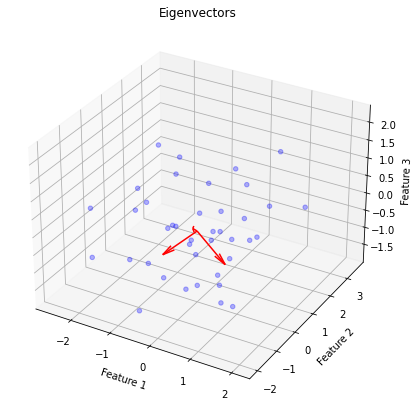

In [12]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(df['feature1'], df['feature2'],
           df['feature3'], color='blue', alpha=0.3)

mean = df.iloc[:,0:3].mean()

for v in eigen_vectors.T:
    ax.quiver(mean[0], mean[1], mean[2],
              v[0], v[1], v[2],
              color='red', length=1)

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')

plt.title('Eigenvectors')
plt.show()

In [13]:
indices = np.argsort(eigen_values)[::-1]

pc = eigen_vectors[:, indices[:2]]

pc

array([[-0.53875915,  0.69363291],
       [-0.65608325,  0.01057596],
       [-0.52848211, -0.72025103]])

In [14]:
transformed_df = np.dot(df.iloc[:,0:3], pc)

In [15]:
new_df = pd.DataFrame(
    transformed_df,
    columns=['PC1','PC2']
)

new_df['target'] = df['target'].values

new_df.head()

,PC1,PC2,target
0,2.302877,0.757593,1
1,0.524464,-0.520221,0
2,0.380275,0.459443,1
3,0.534262,1.773773,1
4,1.610434,-1.747819,1


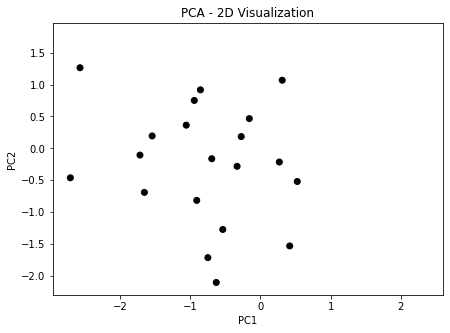

In [17]:
plt.figure(figsize=(7,5))

plt.scatter(new_df['PC1'],
            new_df['PC2'],
            c=new_df['target'])

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title('PCA - 2D Visualization')

plt.show()